# Transformer: forecasting household electric load

**The model.** Instead of reading step by step, *self-attention* lets every hour look directly at every other hour:

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

Attention has no sense of order, so a **positional encoding** is added to each time step.


**The dataset.** *Individual Household Electric Power Consumption* (UCI): about 2 million one-minute readings from one home over four years.
We resample to hourly power and predict **the next hour from the previous 24 hours**.
The same data and split are used in the RNN, LSTM and Transformer notebooks.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "torch": "torch",
    "certifi": "certifi"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "household"
archive = download("https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Already downloaded: data\household\dataset.zip


Files: ['dataset.zip', 'household_power_consumption.txt']


In [4]:
import pandas as pd

# The file is large (about 130 MB), so reading it takes a moment. Missing values are written as "?".
raw = pd.read_csv(DATA_DIR / "household_power_consumption.txt", sep=";", na_values="?",
                  usecols=["Date", "Time", "Global_active_power"], low_memory=False)
raw.index = pd.to_datetime(raw["Date"] + " " + raw["Time"], format="%d/%m/%Y %H:%M:%S")

# One value per hour; short gaps are filled from their neighbors.
load = raw["Global_active_power"].resample("h").mean().interpolate(limit=24).dropna()
print("Hours:", len(load), "| From", load.index[0], "to", load.index[-1])
load.describe().round(3)

Hours: 34327 | From 2006-12-16 17:00:00 to 2010-11-26 21:00:00


count    34327.000
mean         1.092
std          0.897
min          0.124
25%          0.343
50%          0.804
75%          1.578
max          6.561
Name: Global_active_power, dtype: float64

## 2. Build the training windows

In [5]:
import torch
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
LOOKBACK = 24   # hours of history the model sees

# In a time series, the split must follow time. Shuffling would let the model see the future.
n = len(load)
train_end, val_end = int(n * 0.7), int(n * 0.85)
mean, std = load.iloc[:train_end].mean(), load.iloc[:train_end].std()   # statistics from train only
values = (load.to_numpy() - mean) / std

# The clock tells the model about daily and weekly rhythms. Sine and cosine make
# 23:00 and 00:00 close to each other, as they are in reality.
hour = load.index.hour.to_numpy()
day = load.index.dayofweek.to_numpy()
features = np.column_stack([values, np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24),
                            np.sin(2 * np.pi * day / 7), np.cos(2 * np.pi * day / 7)])

def make_windows(start, end):
    """Build (24 hours of features) -> (next hour's load) pairs for targets in [start, end)."""
    positions = range(max(start, LOOKBACK), end)
    inputs = np.stack([features[p - LOOKBACK:p] for p in positions])
    targets = values[list(positions)]
    return torch.tensor(inputs, dtype=torch.float32), torch.tensor(targets, dtype=torch.float32)

X_train, y_train = make_windows(0, train_end)
X_val, y_val = make_windows(train_end, val_end)
X_test, y_test = make_windows(val_end, n)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True, num_workers=0)
print("Windows:", X_train.shape, X_val.shape, X_test.shape)

Windows: torch.Size([24004, 24, 5]) torch.Size([5149, 24, 5]) torch.Size([5150, 24, 5])


## 3. Define the model

In [6]:
import torch.nn as nn

class TransformerForecaster(nn.Module):
    def __init__(self, n_features, length, d_model=64, heads=4, layers=2):
        super().__init__()
        self.embed = nn.Linear(n_features, d_model)                     # features -> model size
        self.position = nn.Parameter(torch.zeros(1, length, d_model))   # learned position of each hour
        block = nn.TransformerEncoderLayer(d_model, heads, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(block, num_layers=layers)
        self.output = nn.Linear(d_model, 1)

    def forward(self, x):
        encoded = self.encoder(self.embed(x) + self.position)
        return self.output(encoded[:, -1]).squeeze(-1)

model = TransformerForecaster(n_features=X_train.shape[2], length=LOOKBACK).to(device)


n_params = sum(p.numel() for p in model.parameters())
print(model)
print("Trainable parameters:", f"{n_params:,}")

TransformerForecaster(
  (embed): Linear(in_features=5, out_features=64, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (output): Linear(in_features=64, out_features=1, bias=True)
)
Trainable parameters: 68,929


## 4. Train with early stopping

In [7]:
MODEL_NAME = "Transformer"
MAX_EPOCHS, PATIENCE, LR = 25, 5, 1e-3

import copy
import time

def predict(model, inputs, batch_size=2000):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(inputs[i:i + batch_size].to(device)).cpu() for i in range(0, len(inputs), batch_size)])

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = {"train": [], "val": []}
best_val, best_state, wait = float("inf"), None, 0

start = time.time()
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    total = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        # Gradient clipping stops exploding gradients, a classic problem of sequence models.
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total += loss.item() * len(xb)

    val_loss = float(loss_fn(predict(model, X_val), y_val))
    history["train"].append(total / len(X_train))
    history["val"].append(val_loss)
    print(f"Epoch {epoch:2d}  train MSE {history['train'][-1]:.4f}  val MSE {val_loss:.4f}")

    if val_loss < best_val - 1e-4:       # early stopping
        best_val, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping.")
            break

train_seconds = time.time() - start
model.load_state_dict(best_state)

Epoch  1  train MSE 0.4571  val MSE 0.3841


Epoch  2  train MSE 0.4086  val MSE 0.3758


Epoch  3  train MSE 0.3984  val MSE 0.3589


Epoch  4  train MSE 0.3854  val MSE 0.3526


Epoch  5  train MSE 0.3806  val MSE 0.3468


Epoch  6  train MSE 0.3753  val MSE 0.3494


Epoch  7  train MSE 0.3712  val MSE 0.3476


Epoch  8  train MSE 0.3701  val MSE 0.3581


Epoch  9  train MSE 0.3708  val MSE 0.3546


Epoch 10  train MSE 0.3690  val MSE 0.3528
Early stopping.


<All keys matched successfully>

## 5. Evaluate on the final 15% of the timeline

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

to_kw = lambda z: z * std + mean      # convert back to real units
y_true = to_kw(y_test.numpy())
y_pred = to_kw(predict(model, X_test).numpy())

rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

# A forecast is only useful if it beats simple rules, so always compare with baselines.
last_hour = to_kw(X_test[:, -1, 0].numpy())      # "next hour equals this hour"
same_hour_yesterday = to_kw(X_test[:, 0, 0].numpy())
rmse_last = float(np.sqrt(mean_squared_error(y_true, last_hour)))
rmse_day = float(np.sqrt(mean_squared_error(y_true, same_hour_yesterday)))

print(f"Model:                RMSE {rmse:.4f} kW | MAE {mae:.4f} kW | R2 {r2:.4f}")
print(f"Baseline, last hour:  RMSE {rmse_last:.4f} kW")
print(f"Baseline, yesterday:  RMSE {rmse_day:.4f} kW")
print(f"Training time: {train_seconds:.0f} s, epochs: {len(history['train'])}")

Model:                RMSE 0.4770 kW | MAE 0.3312 kW | R2 0.5451
Baseline, last hour:  RMSE 0.5814 kW
Baseline, yesterday:  RMSE 0.7588 kW
Training time: 310 s, epochs: 10


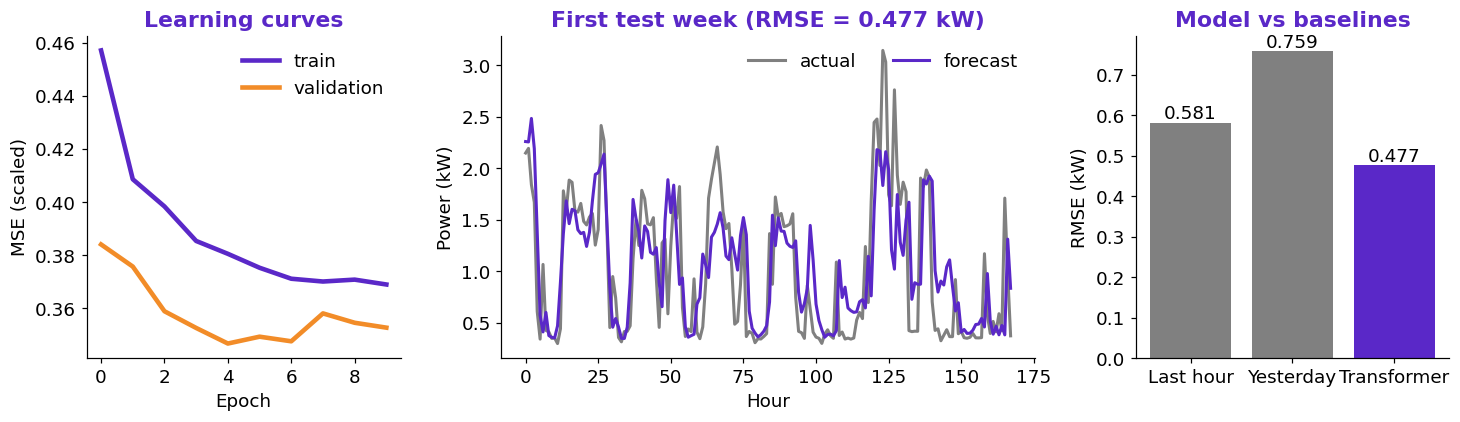

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4), gridspec_kw={"width_ratios": [1, 1.7, 1]})
ax[0].plot(history["train"], color=PURPLE, lw=3, label="train")
ax[0].plot(history["val"], color=ORANGE, lw=3, label="validation")
ax[0].set(title="Learning curves", xlabel="Epoch", ylabel="MSE (scaled)")
ax[0].legend()

week = 24 * 7
ax[1].plot(y_true[:week], color="gray", lw=2, label="actual")
ax[1].plot(y_pred[:week], color=PURPLE, lw=2, label="forecast")
ax[1].set(title=f"First test week (RMSE = {rmse:.3f} kW)", xlabel="Hour", ylabel="Power (kW)")
ax[1].legend(loc="upper right", ncol=2)

names = ["Last hour", "Yesterday", MODEL_NAME]
values = [rmse_last, rmse_day, rmse]
bars = ax[2].bar(names, values, color=["gray", "gray", PURPLE])
for bar, value in zip(bars, values):
    ax[2].text(bar.get_x() + bar.get_width() / 2, value, f"{value:.3f}", ha="center", va="bottom")
ax[2].set(title="Model vs baselines", ylabel="RMSE (kW)")
fig.tight_layout()
plt.show()

In [10]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "05_transformer.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "Transformer",
    "dataset": "Household Electric Power (UCI)",
    "n_samples": int(len(load)),
    "metrics": {"RMSE (kW)": round(rmse, 4), "MAE (kW)": round(float(mae), 4), "R2": round(float(r2), 4), "Baseline RMSE (last hour)": round(rmse_last, 4), "Parameters": n_params, "Train time (s)": round(train_seconds)},
}
(results_dir / "05_transformer.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "Transformer",
  "dataset": "Household Electric Power (UCI)",
  "n_samples": 34327,
  "metrics": {
    "RMSE (kW)": 0.477,
    "MAE (kW)": 0.3312,
    "R2": 0.5451,
    "Baseline RMSE (last hour)": 0.5814,
    "Parameters": 68929,
    "Train time (s)": 310
  }
}


## What to remember
- Transformers shine on long sequences and large datasets. With 24 steps and modest data, they have no automatic advantage.
- Always compare a forecast with simple baselines.
- **Try it yourself:** change `LOOKBACK` to 48 and compare.